In [21]:
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf

life_table = pd.read_csv('lifeTable.csv')
cash_rates = pd.read_csv('cash_rate.csv')
rba = cash_rates[['Year', 'RBA']]

In [ ]:

tickers = {
    'Aus_Shares':   'VAS.AX',  
    'Intl_Shares':  'VGS.AX',  
    'Property':     'VAP.AX',   
    'Infrastructure': 'IFRA.AX',
    'Aus_Bonds':    'VAF.AX',  
    'Intl_Bonds':   'VIF.AX', 
    'Cash':         'AAA.AX'
}


prices = yf.download(list(tickers.values()), start='2000-01-01', interval='1mo',
                     auto_adjust=True, progress=False)['Close']
prices = prices.rename(columns={v: k for k, v in tickers.items()})
prices = prices[list(tickers.keys())]


monthly_returns = prices.pct_change().dropna()

annual_mean = monthly_returns.mean() * 12
annual_cov = monthly_returns.cov() * 12
annual_var = np.diag(annual_cov)
annual_vol = np.sqrt(annual_var)
correlation = monthly_returns.corr()

Data from 2016-05-01 to 2026-10-01 (126 months)



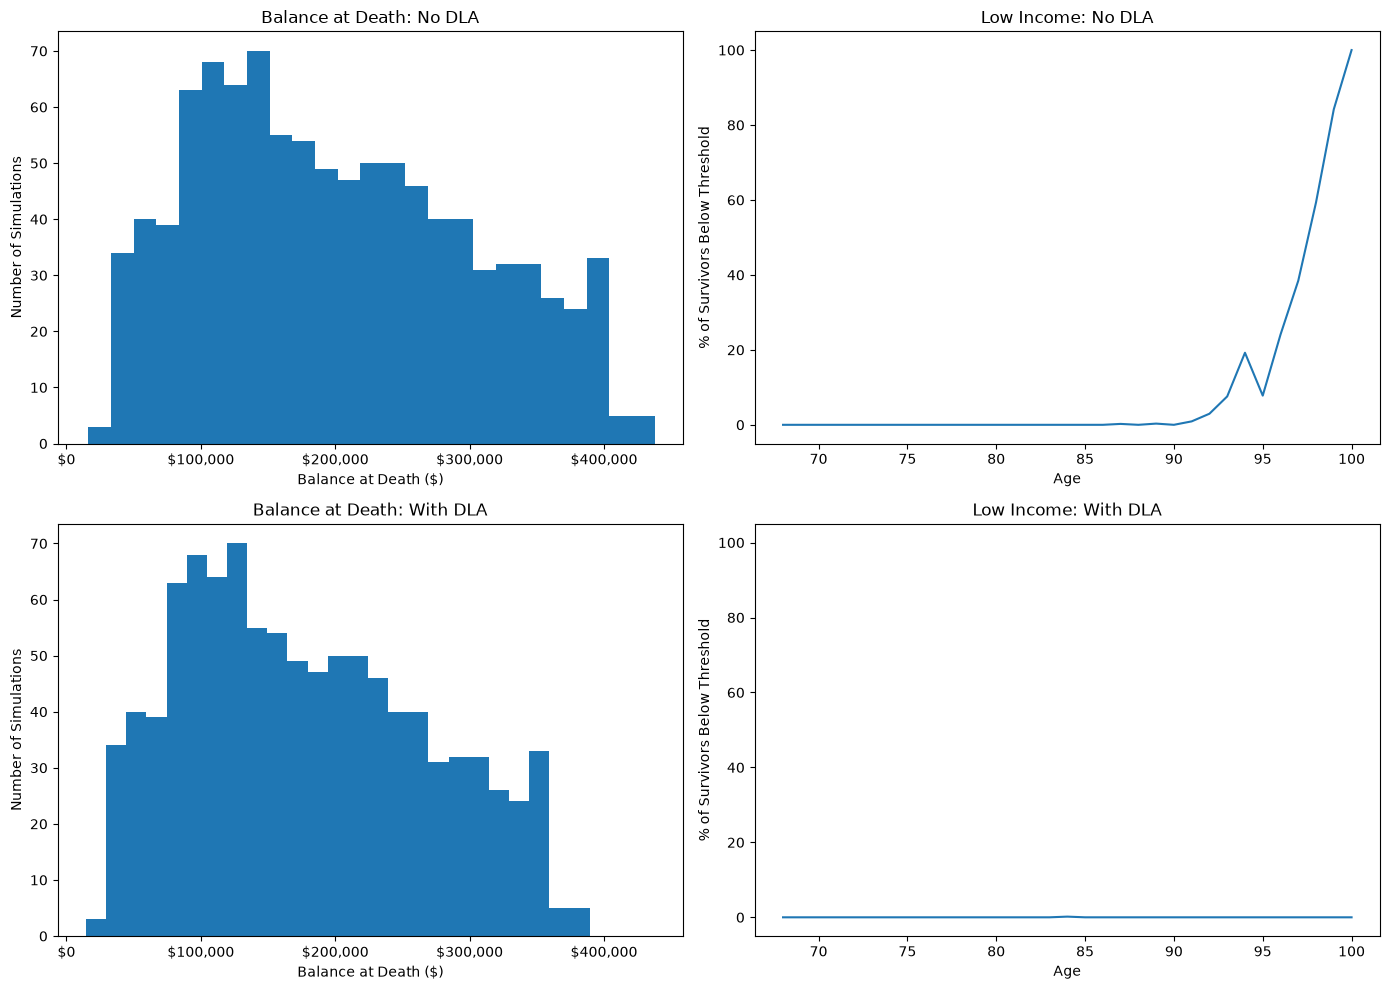

Premium: $44,182
Mean bequest, no DLA: $201,166
Mean bequest, DLA: $178,946
Person-years below threshold, no DLA: 120
Person-years below threshold, DLA: 1


In [32]:
random.seed(1)
weights = {
    "Conservative": [0.1, 0.12, 0.04, 0.04, 0.25, 0.2, 0.25],
    "Balanced": [0.18, 0.2, 0.06, 0.06, 0.2, 0.15, 0.15],
    "Growth": [0.25, 0.3, 0.075, 0.075, 0.12, 0.1, 0.08]
}


survival_rate.iloc[100:] = 0
min_drawdown_rates = {
    65: 0.05,
    74: 0.05,
    79: 0.06,
    84: 0.07,
    89: 0.09,
    94: 0.11,
    100: 0.14
}
key_list = list(min_drawdown_rates.keys())

max_pension = 1237.70 * 26
assets_threshold = 333_000
assets_taper = 78
income_free_area = 226 * 26
income_taper = 0.5
deeming_threshold = 66_800
deeming_lower = 0.0175
deeming_upper = 0.0375
inflation = 0.025

def age_pension(balance, age, dla_price = 0, dla_income = 0,
                dla_asset_pct = 0.6, dla_asset_pct_later = 0.3, dla_switch_age = 84,
                dla_income_pct = 0.6):
    if age <= dla_switch_age:
        dla_assets = dla_price * dla_asset_pct
    else:
        dla_assets = dla_price * dla_asset_pct_later
    total_assets = balance + dla_assets
    assets_pension = max_pension - assets_taper * max(0, total_assets - assets_threshold) / 1000

    deemed_income = (min(balance, deeming_threshold) * deeming_lower
                     + max(0, balance - deeming_threshold) * deeming_upper)
    total_income = deemed_income + dla_income * dla_income_pct
    income_pension = max_pension - income_taper * max(0, total_income - income_free_area)

    return max(0, min(assets_pension, income_pension, max_pension))

def dla_income_for_target(target, price_per_dollar, age = 85):
    low, high = 0, target
    for _ in range(50):
        x = (low + high) / 2
        total = x + age_pension(0, age, dla_price = price_per_dollar * x, dla_income = x)
        if total < target:
            low = x
        else:
            high = x
    return high

def dla_price_per_dollar(age1 = 67, deferral_age = 85, max_age = 100, loading = 0.1):
    px = survival_rate['Australia_Male']
    cash_rate = [rba['RBA'][120]]
    for t in range(max_age - age1):
        cash_rate.append(cash_rate[-1] + kappa * (theta - cash_rate[-1]))
    v = np.cumprod([1] + [1 / (1 + r / 100 - inflation) for r in cash_rate[:-1]])
    pv = 0
    tpx = 1
    for t in range(0, max_age - age1 + 1):
        if age1 + t >= deferral_age:
            pv += tpx * v[t]
        tpx *= px[age1 + t]
    return pv * (1 + loading)

price_per_dollar = dla_price_per_dollar()
dla_income = dla_income_for_target(40_000, price_per_dollar)
premium = price_per_dollar * dla_income
dla_income2 = dla_income_for_target(40_000, 5.65)
premium2 = 5.65 * dla_income2

def monte_carlo_simulation (age1 = 67, abp_balance = 400_000, return_type = "Conservative", premium_val = premium):
    investment_type = {
        "Conservative": 0,
        "Balanced": 1,
        "Growth": 2
    }
    balance_distribution = []
    balance_distribution_dla = []
    low_income_number = {
        x: 0 for x in range(67, 101)
    }
    low_income_number_dla = {
        x: 0 for x in range(67, 101)
    }
    alive_count = {
    x: 0 for x in range(67, 101)
    }   
    for x in range(number_of_simulations):
        returns_dict = {
        }
        returns_list = np.random.multivariate_normal(annual_mean, annual_cov, size = 33)
        for key, value in weights.items():
            returns_dict[key] = []
            for array in returns_list:
                returns_dict[key].append(value @ array)
        current_age = age1
        retirement_balance = abp_balance
        retirement_balance_dla = abp_balance - premium_val
        px_male =  survival_rate['Australia_Male'][current_age]
        income_list = []
        income_list_dla = []
        while random.random() < px_male:
            current_age += 1
            for n in range(1, len(key_list)):
                if current_age <= key_list[n] and current_age > key_list[n-1]:
                    drawdown = min_drawdown_rates[key_list[n]]
                    break 
            pension = age_pension(retirement_balance, current_age)
            income = retirement_balance * drawdown + pension
            option_list = list(returns_dict.values())
            option_returns = option_list[investment_type[return_type]]
            
            dla_payment = dla_income if current_age >= 85 else 0
            pension_dla = age_pension(retirement_balance_dla, current_age, dla_price = premium_val, dla_income = dla_payment)
            income_dla = retirement_balance_dla * drawdown + pension_dla + dla_payment

            r = option_returns[current_age - age1 - 1] - inflation
            retirement_balance = (retirement_balance - retirement_balance * drawdown) * (1 + r)
            retirement_balance_dla = (retirement_balance_dla - retirement_balance_dla * drawdown) * (1 + r)
        
            px_male = survival_rate['Australia_Male'][current_age]
            income_list.append(income)
            income_list_dla.append(income_dla)

            alive_count[current_age] += 1
            if income < 40_000:
                low_income_number[current_age] += 1
            if income_dla < 40_000:
                low_income_number_dla[current_age] += 1
        balance_distribution.append(retirement_balance)
        balance_distribution_dla.append(retirement_balance_dla)
    plot_ages = [age for age in alive_count if alive_count[age] > 0]
    low_prob = [low_income_number[age] / alive_count[age] * 100 for age in plot_ages]
    low_prob_dla = [low_income_number_dla[age] / alive_count[age] * 100 for age in plot_ages]

    fig, axs = plt.subplots(2, 2, figsize = (14, 10), sharex = 'col', sharey = 'col')
    dollar_format = plt.FuncFormatter(lambda x, _: f'${x:,.0f}')

    axs[0, 0].hist(balance_distribution, bins = 25)
    axs[0, 0].set_title('Balance at Death: No DLA')
    axs[0, 0].set_xlabel('Balance at Death ($)')
    axs[0, 0].set_ylabel('Number of Simulations')
    axs[0, 0].xaxis.set_major_formatter(dollar_format)

    axs[0, 1].plot(plot_ages, low_prob)
    axs[0, 1].set_title('Low Income: No DLA')
    axs[0, 1].set_xlabel('Age')
    axs[0, 1].set_ylabel('% of Survivors Below Threshold')

    axs[1, 0].hist(balance_distribution_dla, bins = 25)
    axs[1, 0].set_title('Balance at Death: With DLA')
    axs[1, 0].set_xlabel('Balance at Death ($)')
    axs[1, 0].set_ylabel('Number of Simulations')
    axs[1, 0].xaxis.set_major_formatter(dollar_format)

    axs[1, 1].plot(plot_ages, low_prob_dla)
    axs[1, 1].set_title('Low Income: With DLA')
    axs[1, 1].set_xlabel('Age')
    axs[1, 1].set_ylabel('% of Survivors Below Threshold')
    axs[0, 0].tick_params(labelbottom = True)
    axs[0, 1].tick_params(labelbottom = True)

    plt.tight_layout()
    plt.show()
    print(f"Premium: ${premium2:,.0f}")
    print(f"Mean bequest, no DLA: ${np.mean(balance_distribution):,.0f}")
    print(f"Mean bequest, DLA: ${np.mean(balance_distribution_dla):,.0f}")
    ever_low = sum(low_income_number.values())
    print(f"Person-years below threshold, no DLA: {ever_low}")
    print(f"Person-years below threshold, DLA: {sum(low_income_number_dla.values())}")

monte_carlo_simulation(return_type = 'Conservative', premium_val= premium2)
            

